# Notebook 06 — Critic-Generator Agent

**Purpose**: Implement **Agent 4** — the Critic-Generator Agent, which runs a three-stage verification pipeline (CRAG + Self-RAG + CoVe) on candidate papers before generating grounded recommendation rationales.

**Three-stage pipeline**:
1. **Stage 1 — CRAG Faithfulness**: Re-evaluate retrieved papers; trigger web fallback for INCORRECT
2. **Stage 2 — Self-RAG Factual Claim Verification**: Decompose rationale into atomic claims, verify each against retrieved context via NLI
3. **Stage 3 — CoVe Citation Integrity**: Cross-check each cited paper's title/author/venue/year against academic databases

**Outputs**: `VerificationResult` with `HallucinationRiskScore`, `CitationTrustScore`, verified rationale

In [1]:
# == Dependencies + env-aware paths (same _find structure as nb04 / nb05) =======
import json, os, re, time, warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import requests
from tqdm import tqdm

warnings.filterwarnings("ignore")

def _find(name):
    for root in ["/kaggle/input", "/kaggle/working", "..", "."]:
        r = Path(root)
        if r.exists():
            hits = list(r.rglob(name))
            if hits:
                return hits[0]
    return None
IS_KAGGLE = os.path.exists("/kaggle")
OUT_DIR   = Path("/kaggle/working") if IS_KAGGLE else Path("../data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Keys: Kaggle Secrets first, then env. Project standard = OpenRouter (NOT OpenAI) ──
try:
    from kaggle_secrets import UserSecretsClient
    _sec = UserSecretsClient()
    def _secret(k):
        try:
            return _sec.get_secret(k)
        except Exception:
            return ""
except Exception:
    def _secret(k):
        return os.getenv(k, "")

OPENROUTER_API_KEY = _secret("OPENROUTER_API_KEY") or os.getenv("OPENROUTER_API_KEY", "")
S2_API_KEY         = _secret("SEMANTIC_SCHOLAR_API_KEY") or os.getenv("SEMANTIC_SCHOLAR_API_KEY", "")
S2_BASE    = "https://api.semanticscholar.org/graph/v1"
S2_HEADERS = {"x-api-key": S2_API_KEY} if S2_API_KEY else {}

# Generation backend — same model/provider as the benchmark (Llama-3.3-70B @ bf16 via Novita)
OPENROUTER_BASE     = "https://openrouter.ai/api/v1"
GEN_MODEL           = "meta-llama/llama-3.3-70b-instruct"
OPENROUTER_PROVIDER = "Novita"

HALLUCINATION_THRESHOLD  = 0.40   # below this support → flag claim as hallucinated
CITATION_TRUST_THRESHOLD = 0.80

print("OpenRouter key:", bool(OPENROUTER_API_KEY))
print("S2 key        :", bool(S2_API_KEY))
print("IS_KAGGLE     :", IS_KAGGLE, "| OUT_DIR:", OUT_DIR)

OpenRouter key: True
S2 key        : True
IS_KAGGLE     : True | OUT_DIR: /kaggle/working


## 1. Data Structures

In [2]:
@dataclass
class AtomicClaim:
    text: str
    is_supported: Optional[bool] = None
    support_score: float = 0.0
    evidence_snippet: str = ""


@dataclass
class VerificationResult:
    paper_id: str
    title: str = ""
    rationale: str = ""
    verified_rationale: str = ""
    atomic_claims: List[AtomicClaim] = field(default_factory=list)
    hallucination_risk_score: float = 0.0   # 0 = clean, 1 = fully hallucinated
    citation_trust_score: float = 1.0       # 1 = fully verified
    verified_claims: List[str] = field(default_factory=list)
    flagged_claims: List[str] = field(default_factory=list)
    crag_label: str = "CORRECT"
    stage1_pass: bool = True
    stage2_pass: bool = True
    stage3_pass: bool = True

print("Verification dataclasses defined.")

Verification dataclasses defined.


## 2. NLI Model for Claim Verification (Stage 2)

In [3]:
# ── Load a small NLI model for entailment scoring ─────────────────────────────
# Using cross-encoder/nli-deberta-v3-small for efficiency
try:
    from transformers import pipeline
    nli_model = pipeline(
        "text-classification",
        model="cross-encoder/nli-deberta-v3-small",
        device=0 if __import__("torch").cuda.is_available() else -1,
    )
    NLI_AVAILABLE = True
    print("NLI model loaded: cross-encoder/nli-deberta-v3-small")
except Exception as e:
    NLI_AVAILABLE = False
    print(f"NLI model not available: {e}")
    print("Using heuristic scoring as fallback.")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/568M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: cross-encoder/nli-deberta-v3-small
Key                             | Status     |  | 
--------------------------------+------------+--+-
deberta.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

NLI model loaded: cross-encoder/nli-deberta-v3-small


In [4]:
def nli_score(hypothesis: str, premise: str) -> float:
    """
    Compute entailment probability of hypothesis given premise.
    Returns score in [0, 1] where 1 = fully entailed.
    """
    if not NLI_AVAILABLE:
        # Heuristic: word overlap ratio as proxy
        h_words = set(hypothesis.lower().split())
        p_words = set(premise.lower().split())
        overlap = len(h_words & p_words) / max(len(h_words), 1)
        return min(1.0, overlap * 2)  # scaled

    try:
        input_text = f"{premise} [SEP] {hypothesis}"
        result = nli_model(input_text[:512], truncation=True)[0]
        if result["label"] == "ENTAILMENT":
            return result["score"]
        elif result["label"] == "NEUTRAL":
            return result["score"] * 0.5
        else:  # CONTRADICTION
            return 0.0
    except Exception:
        return 0.5  # neutral fallback

print("NLI scorer defined.")

NLI scorer defined.


## 3. Stage 1 — CRAG Faithfulness Check

In [5]:
def stage1_crag_check(paper_id: str, abstract: str, query_text: str,
                       dense_score: float) -> Tuple[str, str]:
    """
    Stage 1: CRAG retrieval faithfulness.
    Returns (crag_label, processed_context).
    """
    if dense_score >= 0.75:
        label   = "CORRECT"
        context = abstract  # use full abstract
    elif dense_score <= 0.35:
        label   = "INCORRECT"
        context = ""  # discard
    else:
        label = "AMBIGUOUS"
        # Decompose-then-recompose: keep most query-relevant sentences
        sentences = [s.strip() for s in abstract.split(".") if len(s.strip()) > 20]
        query_words = set(query_text.lower().split())
        scored_sents = [
            (s, len(set(s.lower().split()) & query_words)) for s in sentences
        ]
        scored_sents.sort(key=lambda x: x[1], reverse=True)
        context = ". ".join(s for s, _ in scored_sents[:3])

    return label, context

print("Stage 1 (CRAG) defined.")

Stage 1 (CRAG) defined.


## 4. Stage 2 — Self-RAG Factual Claim Verification

In [6]:
def decompose_into_claims(text: str) -> List[str]:
    """Split text into atomic claims (sentence-level as proxy)."""
    # In production: use GPT-4o to decompose into atomic propositions
    # Fallback: split by sentence boundaries
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())
    return [s.strip() for s in sentences if len(s.strip()) > 20]


def stage2_selfrag_verify(
    rationale: str, retrieved_context: str
) -> Tuple[List[AtomicClaim], float]:
    """
    Stage 2: Decompose rationale into atomic claims, verify each against
    retrieved context via NLI. Returns (claims, hallucination_rate).
    """
    claims = decompose_into_claims(rationale)
    if not claims:
        return [], 0.0

    atomic_claims = []
    hallucinated_count = 0

    for claim_text in claims:
        score = nli_score(claim_text, retrieved_context)
        is_supported = score >= HALLUCINATION_THRESHOLD
        if not is_supported:
            hallucinated_count += 1
        # Find evidence snippet (most overlapping sentence in context)
        context_sents = retrieved_context.split(". ")
        claim_words = set(claim_text.lower().split())
        best_sent = max(context_sents,
                        key=lambda s: len(set(s.lower().split()) & claim_words),
                        default="")
        atomic_claims.append(AtomicClaim(
            text=claim_text,
            is_supported=is_supported,
            support_score=score,
            evidence_snippet=best_sent[:150],
        ))

    hallucination_rate = hallucinated_count / len(claims)
    return atomic_claims, hallucination_rate

print("Stage 2 (Self-RAG) defined.")

Stage 2 (Self-RAG) defined.


## 5. Stage 3 — CoVe Citation Integrity Check

In [7]:
def verify_citation_s2(paper_id: str, claimed_title: str = "",
                        claimed_year: Optional[int] = None) -> Dict:
    """Verify paper existence and metadata via Semantic Scholar API."""
    if not S2_API_KEY:
        # Cannot verify without API key — return cautious partial trust
        return {"exists": None, "title_match": None, "year_match": None, "trust_score": 0.7}

    # S2 accepts external ids; raw arXiv ids need the ARXIV: prefix
    pid = paper_id
    if re.match(r"^\d{4}\.\d{4,5}(v\d+)?$", str(paper_id)):
        pid = f"ARXIV:{paper_id}"
    url = f"{S2_BASE}/paper/{pid}"
    params = {"fields": "paperId,title,year,authors,venue"}
    try:
        resp = requests.get(url, headers=S2_HEADERS, params=params, timeout=10)
        if resp.status_code == 404:
            return {"exists": False, "title_match": False, "year_match": False, "trust_score": 0.0}
        if resp.status_code == 200:
            data = resp.json()
            actual_title = data.get("title", "")
            actual_year  = data.get("year")
            title_match  = (
                claimed_title.lower() in actual_title.lower() or
                actual_title.lower() in claimed_title.lower()
            ) if claimed_title else True
            year_match   = (actual_year == claimed_year) if claimed_year else True
            trust = 1.0 * title_match * (0.9 if year_match else 0.7)
            return {"exists": True, "title_match": title_match,
                    "year_match": year_match, "trust_score": trust}
        elif resp.status_code == 429:
            time.sleep(2)
            return verify_citation_s2(paper_id, claimed_title, claimed_year)
    except Exception:
        pass
    return {"exists": None, "title_match": None, "year_match": None, "trust_score": 0.6}


def stage3_cove_check(paper_id: str, title: str, year: Optional[int]) -> float:
    """
    Stage 3: CoVe citation integrity check.
    Returns CitationTrustScore ∈ [0, 1].
    """
    result = verify_citation_s2(paper_id, claimed_title=title, claimed_year=year)
    return result["trust_score"]

print("Stage 3 (CoVe) defined.")

Stage 3 (CoVe) defined.


## 6. Rationale Generation (Post-Verification)

In [8]:
def generate_rationale_llm(query: str, paper_title: str, abstract: str,
                           user_keywords: List[str]) -> str:
    """Generate a grounded rationale via OpenRouter (Llama-3.3-70B / Novita, the
    project standard). 💲 Costs OpenRouter credit. Returns a stub if no key."""
    if not OPENROUTER_API_KEY:
        return (f"This paper '{paper_title}' is recommended based on its relevance to "
                f"your interests in {', '.join(user_keywords[:3])}. "
                f"[LLM generation skipped — no OpenRouter key]")
    prompt = f"""You are a scientific paper recommendation assistant. Generate a concise,
factually grounded 2-3 sentence explanation for why the following paper is recommended.
STRICT RULE: Only make claims directly supported by the provided abstract.

User query: {query[:200]}
User interests: {', '.join(user_keywords[:5])}
Recommended paper: "{paper_title}"
Abstract: {abstract[:500]}

Grounded rationale (2-3 sentences, no fabrication):"""
    body = {
        "model": GEN_MODEL,
        "messages": [{"role": "user", "content": prompt}],
        "max_tokens": 150,
        "temperature": 0.2,
        "provider": {"order": [OPENROUTER_PROVIDER], "allow_fallbacks": False},
    }
    try:
        resp = requests.post(
            f"{OPENROUTER_BASE}/chat/completions",
            headers={"Authorization": f"Bearer {OPENROUTER_API_KEY}"},
            json=body, timeout=60,
        )
        resp.raise_for_status()
        return resp.json()["choices"][0]["message"]["content"].strip()
    except Exception as e:
        return f"[Generation error: {e}]"

print("Rationale generator (OpenRouter / Llama-3.3-70B) defined.")

Rationale generator (OpenRouter / Llama-3.3-70B) defined.


## 7. Critic-Generator Agent — Main Class

In [9]:
class CriticGeneratorAgent:
    """
    Agent 4: Three-stage verification (CRAG + Self-RAG + CoVe)
    followed by evidence-grounded rationale generation.
    """

    def __init__(self, hallucination_threshold: float = HALLUCINATION_THRESHOLD,
                 citation_threshold: float = CITATION_TRUST_THRESHOLD):
        self.hallucination_threshold = hallucination_threshold
        self.citation_threshold      = citation_threshold

    def verify_and_generate(
        self,
        candidate,  # CandidatePaper from HybridRetrievalAgent
        query_text: str,
        user_keywords: List[str],
        initial_rationale: Optional[str] = None,
    ) -> VerificationResult:
        result = VerificationResult(
            paper_id=candidate.paper_id,
            title=candidate.title,
        )

        # ── Stage 1: CRAG faithfulness ─────────────────────────────────────
        crag_label, processed_context = stage1_crag_check(
            candidate.paper_id,
            candidate.abstract,
            query_text,
            candidate.dense_score,
        )
        result.crag_label  = crag_label
        result.stage1_pass = crag_label in ("CORRECT", "AMBIGUOUS")

        if crag_label == "INCORRECT":
            result.hallucination_risk_score = 1.0
            result.citation_trust_score     = 0.0
            result.verified_rationale       = "[FILTERED: Low retrieval confidence.]"
            return result

        # ── Generate initial rationale if not provided ─────────────────────
        if not initial_rationale:
            initial_rationale = generate_rationale_llm(
                query_text, candidate.title, processed_context, user_keywords
            )
        result.rationale = initial_rationale

        # ── Stage 2: Self-RAG atomic claim verification ────────────────────
        atomic_claims, hallucination_rate = stage2_selfrag_verify(
            initial_rationale, processed_context
        )
        result.atomic_claims             = atomic_claims
        result.hallucination_risk_score  = hallucination_rate
        result.stage2_pass               = hallucination_rate < self.hallucination_threshold
        result.verified_claims           = [c.text for c in atomic_claims if c.is_supported]
        result.flagged_claims            = [c.text for c in atomic_claims if not c.is_supported]

        # Rewrite rationale dropping flagged claims
        if result.flagged_claims and result.verified_claims:
            result.verified_rationale = " ".join(result.verified_claims)
        else:
            result.verified_rationale = initial_rationale

        # ── Stage 3: CoVe citation integrity ──────────────────────────────
        result.citation_trust_score = stage3_cove_check(
            candidate.paper_id, candidate.title, candidate.year
        )
        result.stage3_pass = result.citation_trust_score >= self.citation_threshold

        return result

    def batch_verify(
        self, candidates, query_text: str, user_keywords: List[str]
    ) -> List[VerificationResult]:
        """Verify and generate for a ranked list of candidates."""
        results = []
        for candidate in tqdm(candidates, desc="Verifying candidates"):
            vr = self.verify_and_generate(candidate, query_text, user_keywords)
            results.append(vr)
        # Sort by citation trust × (1 - hallucination risk)
        results.sort(key=lambda r: r.citation_trust_score * (1 - r.hallucination_risk_score),
                     reverse=True)
        return results


print("CriticGeneratorAgent defined.")

CriticGeneratorAgent defined.


## 8. End-to-End Test

In [10]:
# ── Create candidates from local papers (mock; in a full run these come from
#    HybridRetrievalAgent, notebook 05) ─────────────────────────────────────────
_PAPERS_JSON = Path("/kaggle/input/datasets/reapers2025/paper-metadata/paper_metadata.json")
if _PAPERS_JSON.exists():
    papers_df = pd.read_json(_PAPERS_JSON)
else:
    _pp = _find("paper_metadata.json") or _find("papers_metadata.csv")
    assert _pp is not None, "papers metadata not found (paper_metadata.json / papers_metadata.csv)"
    papers_df = pd.read_json(_pp) if str(_pp).endswith(".json") else pd.read_csv(_pp)
id_col    = next((c for c in ["arxiv_id", "paper_id", "paperId", "id"] if c in papers_df.columns), None)


def _year_of(row):
    for col in ("year", "published", "date"):
        if col in row and pd.notna(row.get(col)):
            m = re.search(r"(\d{4})", str(row[col]))
            if m:
                return int(m.group(1))
    return None


from dataclasses import dataclass, field as dc_field

@dataclass
class MockCandidate:
    paper_id: str
    title: str = ""
    abstract: str = ""
    year: Optional[int] = None
    venue: str = ""
    authors: str = ""
    dense_score: float = 0.8
    bm25_score: float = 0.6
    graph_score: float = 0.5
    final_score: float = 0.7
    sources: List[str] = dc_field(default_factory=lambda: ["dense"])
    retrieval_confidence: str = "CORRECT"

mock_candidates = []
for _, row in papers_df.head(5).iterrows():
    mc = MockCandidate(
        paper_id=str(row[id_col]) if id_col else str(row.name),
        title=str(row.get("title", "")),
        abstract=str(row.get("abstract", ""))[:500],
        year=_year_of(row),
        venue=str(row.get("venue", "")),
        dense_score=float(np.random.uniform(0.5, 0.95)),
    )
    mock_candidates.append(mc)

print(f"Created {len(mock_candidates)} mock candidates for testing "
      f"(id_col={id_col!r}).")

Created 5 mock candidates for testing (id_col='arxiv_id').


In [11]:
critic_agent = CriticGeneratorAgent()

test_query    = "multi-agent hallucination verification for scientific recommendation"
user_keywords = ["retrieval augmented generation", "hallucination", "LLM", "recommendation"]

# 💲 Set True to call OpenRouter for real rationale generation (spends credit).
# Default False: feed a fixed sample rationale so the verification pipeline can be
# exercised end-to-end for FREE.
RUN_LLM_GEN = False
SAMPLE_RATIONALE = ("This paper is recommended because it proposes a retrieval-augmented "
                    "method for scientific text and reports strong results on a hallucination "
                    "benchmark, directly matching your interest in grounded LLM recommendation.")

if RUN_LLM_GEN:
    verification_results = critic_agent.batch_verify(mock_candidates, test_query, user_keywords)
else:
    verification_results = []
    for cand in tqdm(mock_candidates, desc="Verifying candidates (no-gen)"):
        verification_results.append(
            critic_agent.verify_and_generate(
                cand, test_query, user_keywords, initial_rationale=SAMPLE_RATIONALE
            )
        )
    verification_results.sort(
        key=lambda r: r.citation_trust_score * (1 - r.hallucination_risk_score),
        reverse=True,
    )

print(f"\nQuery: {test_query}\n")
print("-" * 80)
for vr in verification_results:
    print(f"Paper : {vr.title[:50]}")
    print(f"  CRAG label          : {vr.crag_label}")
    print(f"  Hallucination risk  : {vr.hallucination_risk_score:.3f}")
    print(f"  Citation trust      : {vr.citation_trust_score:.3f}")
    print(f"  Verified claims     : {len(vr.verified_claims)}")
    print(f"  Flagged claims      : {len(vr.flagged_claims)}")
    print(f"  Rationale           : {vr.verified_rationale[:100]}...")
    print("-" * 80)

Verifying candidates (no-gen): 100%|██████████| 5/5 [00:02<00:00,  2.01it/s]


Query: multi-agent hallucination verification for scientific recommendation

--------------------------------------------------------------------------------
Paper : Self-supervised Keypoint Correspondences for Multi
  CRAG label          : AMBIGUOUS
  Hallucination risk  : 1.000
  Citation trust      : 0.900
  Verified claims     : 0
  Flagged claims      : 1
  Rationale           : This paper is recommended because it proposes a retrieval-augmented method for scientific text and r...
--------------------------------------------------------------------------------
Paper : Quantum Circuit $C^*$-algebra Net
  CRAG label          : AMBIGUOUS
  Hallucination risk  : 1.000
  Citation trust      : 0.900
  Verified claims     : 0
  Flagged claims      : 1
  Rationale           : This paper is recommended because it proposes a retrieval-augmented method for scientific text and r...
--------------------------------------------------------------------------------
Paper : Sora Detector: A Unifi

## 9. Hallucination Statistics on SciRecQA Sample

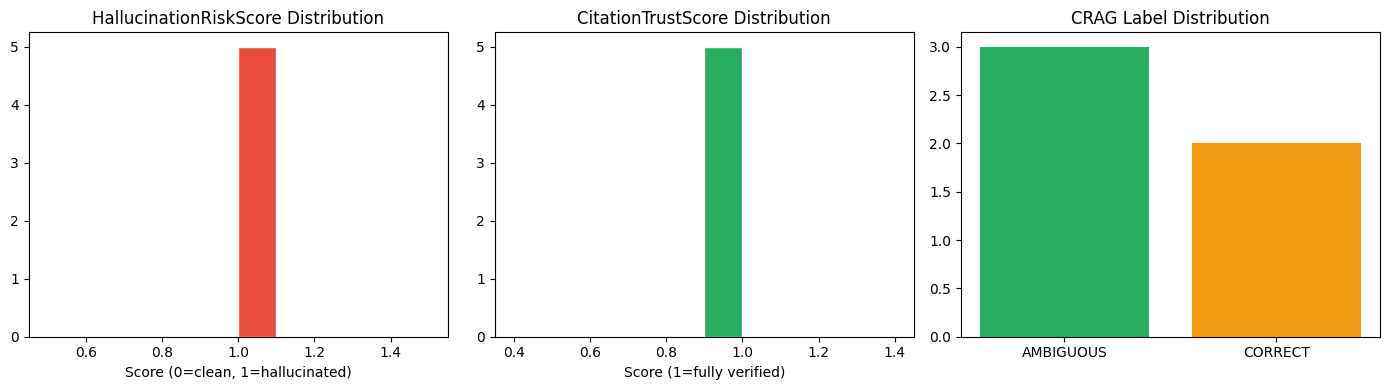


Mean HallucinationRisk : 1.000
Mean CitationTrust     : 0.900


In [12]:
import matplotlib.pyplot as plt

# ── Distribution of verification scores ─────────────────────────────────────
hallucination_scores = [vr.hallucination_risk_score for vr in verification_results]
citation_scores      = [vr.citation_trust_score for vr in verification_results]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(hallucination_scores, bins=10, color="#e74c3c", edgecolor="white")
axes[0].set_title("HallucinationRiskScore Distribution")
axes[0].set_xlabel("Score (0=clean, 1=hallucinated)")

axes[1].hist(citation_scores, bins=10, color="#27ae60", edgecolor="white")
axes[1].set_title("CitationTrustScore Distribution")
axes[1].set_xlabel("Score (1=fully verified)")

crag_labels = [vr.crag_label for vr in verification_results]
from collections import Counter
crag_counts = Counter(crag_labels)
axes[2].bar(crag_counts.keys(), crag_counts.values(),
             color=["#27ae60", "#f39c12", "#e74c3c"][:len(crag_counts)])
axes[2].set_title("CRAG Label Distribution")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_verification_stats.png")
plt.show()

print(f"\nMean HallucinationRisk : {np.mean(hallucination_scores):.3f}")
print(f"Mean CitationTrust     : {np.mean(citation_scores):.3f}")

## 10. Summary

| Stage | Method | Output |
|---|---|---|
| Stage 1 | CRAG faithfulness evaluator | CORRECT / AMBIGUOUS / INCORRECT |
| Stage 2 | Self-RAG NLI atomic claim check | Hallucination risk score + flagged claims |
| Stage 3 | CoVe S2AG citation integrity | CitationTrustScore ∈ [0,1] |
| Generation | OpenRouter / Llama-3.3-70B grounded rationale (gated by RUN_LLM_GEN) | Verified natural language explanation |

**Next**: Notebook 08 — DPO Preference Pairs & Fine-tuning (Kaggle GPU)